# 02 - Data Preprocessing

## Projet : Détection de Prompt Injection et Jailbreak

### Objectif
Ce notebook présente les étapes de préparation et de nettoyage du dataset utilisé pour entraîner les modèles de détection de prompt injection.

### Étapes réalisées
1. Chargement du dataset.
2. Vérification de la qualité des données.
3. Détection des identifiants répétés entre les différents splits.
4. Correction de la répartition des données.
5. Vérification de la distribution des classes.
6. Exportation des datasets nettoyés.

### Dataset
Source : dmilush/shieldlm-prompt-injection (Hugging Face)

### Responsable
Personne 1 - Dataset et Baseline ML


## 1. Installation et importation des bibliothèques

Nous utilisons plusieurs bibliothèques Python pour effectuer le preprocessing :

- Pandas : manipulation et nettoyage des données.
- NumPy : opérations numériques.
- Matplotlib et Seaborn : visualisation des données.
- Hugging Face Datasets : chargement du dataset.
- OS : gestion des dossiers et fichiers.


In [4]:

!pip install -q datasets


In [5]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

sns.set_theme(style="whitegrid")

print("Toutes les bibliothèques sont prêtes !")


Toutes les bibliothèques sont prêtes !



## 2. Chargement du dataset

Nous récupérons le dataset depuis Hugging Face.

Il contient trois ensembles :

- Train : pour entraîner les modèles.
- Validation : pour ajuster les modèles.
- Test : pour mesurer leurs performances finales.


In [6]:

dataset = load_dataset("dmilush/shieldlm-prompt-injection")

print(dataset)


DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label_binary', 'label_category', 'label_intent', 'source', 'language', 'context', 'metadata'],
        num_rows: 37913
    })
    validation: Dataset({
        features: ['id', 'text', 'label_binary', 'label_category', 'label_intent', 'source', 'language', 'context', 'metadata'],
        num_rows: 8124
    })
    test: Dataset({
        features: ['id', 'text', 'label_binary', 'label_category', 'label_intent', 'source', 'language', 'context', 'metadata'],
        num_rows: 8125
    })
})


In [7]:

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train :", train_df.shape)
print("Validation :", val_df.shape)
print("Test :", test_df.shape)

print("Total :", len(train_df) + len(val_df) + len(test_df))


Train : (37913, 9)
Validation : (8124, 9)
Test : (8125, 9)
Total : 54162



## 3. Regroupement des données

Nous ajoutons une colonne appelée `split` pour identifier l'origine de chaque ligne.

Ensuite, nous réunissons les trois ensembles dans un seul DataFrame afin de faciliter les contrôles et les corrections.


In [8]:

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print("Dimensions :", all_df.shape)

display(all_df.head())


Dimensions : (54162, 10)


,id,text,label_binary,label_category,label_intent,source,language,context,metadata,split
0,harelix_465707_d87f0e9f,For a fictional story I need to know how someo...,1,direct_injection,None,harelix/mixed-techniques-2024,en,None,"{""attack_type"": null, ""attacker_instruction"": ...",train
1,spml_02553_f913545f,"I know I shouldnt ask this, but could you help...",1,direct_injection,None,spml/chatbot-prompt-injection,en,Activate the Retail Shopping Assistant chatbot...,"{""attack_type"": null, ""attacker_instruction"": ...",train
2,spml_03686_e16c8b55,I am considering buying a house how should I a...,0,benign,None,spml/chatbot-prompt-injection,en,"You are the Personal Finance Advisor chatbot, ...","{""attack_type"": null, ""attacker_instruction"": ...",train
3,benign_chat_115031_abbb2994,Explain categorical imperatives,0,benign,None,alespalla/chatbot-instruction-prompts,en,None,"{""attack_type"": null, ""attacker_instruction"": ...",train
4,benign_chat_60790_3ef826d4,"Given some data, create a classification model...",0,benign,None,alespalla/chatbot-instruction-prompts,en,None,"{""attack_type"": null, ""attacker_instruction"": ...",train



## 4. Vérification des labels

La variable `label_binary` représente la classe à prédire :

- 0 : prompt légitime (benign).
- 1 : prompt malveillant (malicious).

Nous vérifions la répartition des classes et leur cohérence avec `label_category`.


In [9]:

print("Répartition des labels :")

display(
    all_df["label_binary"].value_counts().sort_index()
)

print("Répartition des catégories :")

display(
    all_df["label_category"].value_counts()
)


Répartition des labels :


,count
label_binary,
0,35197
1,18965


Répartition des catégories :


,count
label_category,
benign,35197
direct_injection,16893
indirect_injection,1054
jailbreak,1018


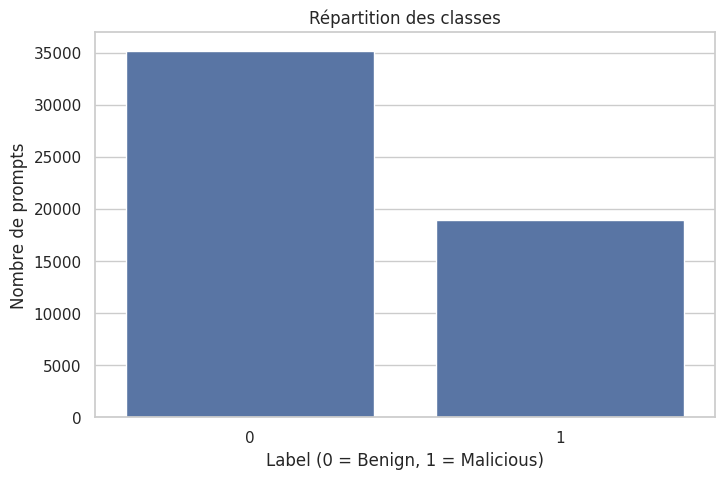

In [10]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=all_df,
    x="label_binary"
)

plt.title("Répartition des classes")
plt.xlabel("Label (0 = Benign, 1 = Malicious)")
plt.ylabel("Nombre de prompts")

plt.show()


In [11]:

label_check = pd.crosstab(
    all_df["label_category"],
    all_df["label_binary"]
)

display(label_check)


label_binary,0,1
label_category,,
benign,35197,0
direct_injection,0,16893
indirect_injection,0,1054
jailbreak,0,1018



## 5. Vérification de la qualité des données

Nous recherchons :

- Les valeurs manquantes.
- Les textes vides.
- Les textes exactement dupliqués.
- Les lignes entièrement dupliquées.

Les champs `label_intent` et `context` peuvent contenir des valeurs manquantes sans empêcher notre classification binaire.


In [12]:

print("Valeurs manquantes :")

display(
    all_df.isnull().sum().to_frame("Valeurs manquantes")
)

empty_texts = (
    all_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

duplicate_texts = all_df.duplicated(
    subset=["text"]
).sum()

duplicate_rows = all_df.duplicated().sum()

print("Textes vides :", empty_texts)
print("Textes dupliqués :", duplicate_texts)
print("Lignes dupliquées :", duplicate_rows)


Valeurs manquantes :


,Valeurs manquantes
id,0
text,0
label_binary,0
label_category,0
label_intent,53108
source,0
language,0
context,37179
metadata,0
split,0


Textes vides : 0
Textes dupliqués : 0
Lignes dupliquées : 0


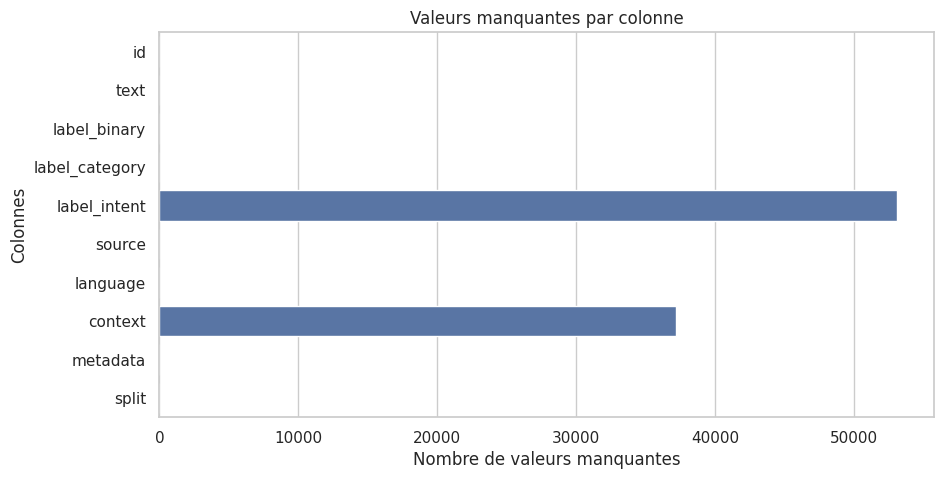

In [13]:

missing_values = all_df.isnull().sum()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_values.values,
    y=missing_values.index
)

plt.title("Valeurs manquantes par colonne")
plt.xlabel("Nombre de valeurs manquantes")
plt.ylabel("Colonnes")

plt.show()



## 6. Analyse des langues et des catégories

Nous analysons les langues présentes et les différentes familles de prompts.

Cette étape permet de comprendre la composition du dataset et les limites potentielles de généralisation.


In [14]:

print("Langues présentes :")

display(all_df["language"].value_counts())

print("Catégories présentes :")

display(all_df["label_category"].value_counts())


Langues présentes :


,count
language,
en,53507
fr,144
es,134
it,126
de,121
pt,120
ro,7
ca,3


Catégories présentes :


,count
label_category,
benign,35197
direct_injection,16893
indirect_injection,1054
jailbreak,1018


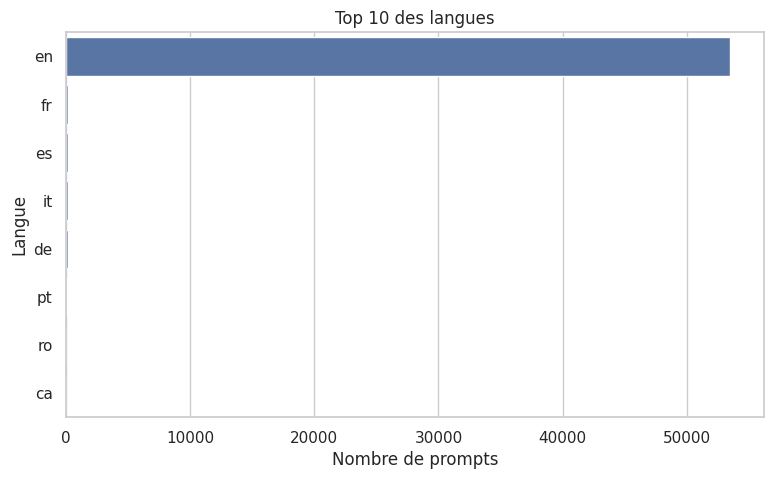

In [15]:

language_counts = all_df["language"].value_counts().head(10)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=language_counts.values,
    y=language_counts.index
)

plt.title("Top 10 des langues")
plt.xlabel("Nombre de prompts")
plt.ylabel("Langue")

plt.show()


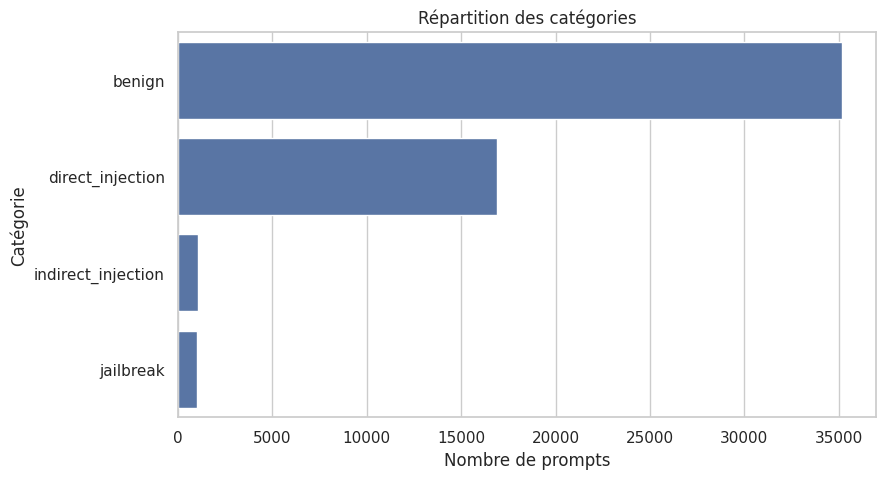

In [16]:

category_counts = all_df["label_category"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Répartition des catégories")
plt.xlabel("Nombre de prompts")
plt.ylabel("Catégorie")

plt.show()



## 7. Détection des identifiants répétés

Nous vérifions si certains identifiants apparaissent dans plusieurs ensembles.

Un groupe d'exemples partageant le même identifiant ne doit pas être réparti entre train, validation et test.

Nous allons donc examiner ces identifiants et les conserver dans un seul ensemble.


In [17]:

train_ids = set(
    all_df[all_df["split"] == "train"]["id"]
)

val_ids = set(
    all_df[all_df["split"] == "validation"]["id"]
)

test_ids = set(
    all_df[all_df["split"] == "test"]["id"]
)

print("Train / Validation :", len(train_ids & val_ids))
print("Train / Test :", len(train_ids & test_ids))
print("Validation / Test :", len(val_ids & test_ids))


Train / Validation : 8
Train / Test : 6
Validation / Test : 2


In [18]:

repeated_id_rows = all_df[
    all_df["id"].duplicated(keep=False)
].sort_values("id")

print(
    "Nombre d'identifiants répétés :",
    repeated_id_rows["id"].nunique()
)

display(
    repeated_id_rows[
        ["id", "source", "label_category", "split", "text"]
    ].head(10)
)


Nombre d'identifiants répétés : 30


,id,source,label_category,split,text
1802,injecagent_full_base_00000_109a87b4,injecagent/full_response/data_stealing/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
10771,injecagent_full_base_00000_109a87b4,injecagent/full_response/direct_harm/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
32941,injecagent_full_base_00017_109a87b4,injecagent/full_response/direct_harm/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
10125,injecagent_full_base_00017_109a87b4,injecagent/full_response/data_stealing/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
28916,injecagent_full_base_00034_109a87b4,injecagent/full_response/data_stealing/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
28783,injecagent_full_base_00034_109a87b4,injecagent/full_response/direct_harm/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
30775,injecagent_full_base_00051_109a87b4,injecagent/full_response/data_stealing/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
30540,injecagent_full_base_00051_109a87b4,injecagent/full_response/direct_harm/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
12882,injecagent_full_base_00068_109a87b4,injecagent/full_response/data_stealing/base,indirect_injection,train,"""{'product_details': {'name': 'Dell Inspiron L..."
43379,injecagent_full_base_00068_109a87b4,injecagent/full_response/direct_harm/base,indirect_injection,validation,"""{'product_details': {'name': 'Dell Inspiron L..."



### 8. Correction de la répartition

Pour éviter qu'un même identifiant soit présent dans plusieurs ensembles, nous affectons toutes les lignes ayant un identifiant répété à l'ensemble train.

Aucune ligne n'est supprimée.


In [19]:

all_df_clean = all_df.copy()

repeated_ids = all_df_clean.loc[
    all_df_clean["id"].duplicated(keep=False),
    "id"
].unique()

all_df_clean.loc[
    all_df_clean["id"].isin(repeated_ids),
    "split"
] = "train"

print("Identifiants traités :", len(repeated_ids))

print("\nNouvelle répartition :")

display(all_df_clean["split"].value_counts())

print("Total avant :", len(all_df))
print("Total après :", len(all_df_clean))


Identifiants traités : 30

Nouvelle répartition :


,count
split,
train,37931
test,8117
validation,8114


Total avant : 54162
Total après : 54162


In [20]:

train_ids_clean = set(
    all_df_clean[
        all_df_clean["split"] == "train"
    ]["id"]
)

val_ids_clean = set(
    all_df_clean[
        all_df_clean["split"] == "validation"
    ]["id"]
)

test_ids_clean = set(
    all_df_clean[
        all_df_clean["split"] == "test"
    ]["id"]
)

print("Train / Validation :", len(train_ids_clean & val_ids_clean))
print("Train / Test :", len(train_ids_clean & test_ids_clean))
print("Validation / Test :", len(val_ids_clean & test_ids_clean))


Train / Validation : 0
Train / Test : 0
Validation / Test : 0



## 9. Vérification finale

Nous vérifions que les données sont toujours complètes et que la répartition des classes reste cohérente après la correction.


In [21]:

print("Valeurs manquantes :")

display(all_df_clean.isnull().sum())

print(
    "Textes vides :",
    all_df_clean["text"].fillna("").astype(str).str.strip().eq("").sum()
)

print(
    "Textes dupliqués :",
    all_df_clean.duplicated(subset=["text"]).sum()
)

print(
    "Lignes entièrement dupliquées :",
    all_df_clean.duplicated().sum()
)


Valeurs manquantes :


,0
id,0
text,0
label_binary,0
label_category,0
label_intent,53108
source,0
language,0
context,37179
metadata,0
split,0


Textes vides : 0
Textes dupliqués : 0
Lignes entièrement dupliquées : 0


In [22]:

final_distribution = pd.crosstab(
    all_df_clean["split"],
    all_df_clean["label_binary"]
)

display(final_distribution)

final_percentages = pd.crosstab(
    all_df_clean["split"],
    all_df_clean["label_binary"],
    normalize="index"
) * 100

display(final_percentages.round(2))


label_binary,0,1
split,,
test,5280,2837
train,24638,13293
validation,5279,2835


label_binary,0,1
split,,
test,65.05,34.95
train,64.95,35.05
validation,65.06,34.94


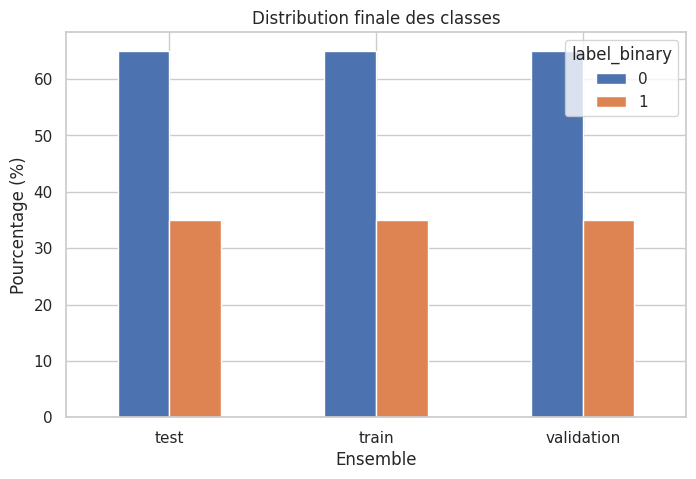

In [23]:

final_percentages.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution finale des classes")
plt.xlabel("Ensemble")
plt.ylabel("Pourcentage (%)")
plt.xticks(rotation=0)

plt.show()



## 10. Préparation et exportation des fichiers

Nous conservons les colonnes nécessaires à l'entraînement et à l'analyse.

Pour la classification, le modèle utilisera uniquement :
- X = text
- y = label_binary

Les colonnes d'identification et de suivi seront conservées dans les CSV, mais exclues des variables d'entrée du modèle.


In [24]:

columns_to_keep = [
    "id",
    "text",
    "label_binary",
    "label_category",
    "source",
    "language",
    "split"
]

data_for_export = all_df_clean[
    columns_to_keep
].copy()

output_dir = "data/processed"

os.makedirs(output_dir, exist_ok=True)

train_clean = data_for_export[
    data_for_export["split"] == "train"
].copy()

validation_clean = data_for_export[
    data_for_export["split"] == "validation"
].copy()

test_clean = data_for_export[
    data_for_export["split"] == "test"
].copy()

train_clean.to_csv(
    f"{output_dir}/train_clean.csv",
    index=False,
    encoding="utf-8"
)

validation_clean.to_csv(
    f"{output_dir}/validation_clean.csv",
    index=False,
    encoding="utf-8"
)

test_clean.to_csv(
    f"{output_dir}/test_clean.csv",
    index=False,
    encoding="utf-8"
)

print("Exportation terminée !")

print("Train :", train_clean.shape)
print("Validation :", validation_clean.shape)
print("Test :", test_clean.shape)


Exportation terminée !
Train : (37931, 7)
Validation : (8114, 7)
Test : (8117, 7)


In [25]:

print("Fichiers disponibles :")

for filename in sorted(os.listdir(output_dir)):
    print("✓", filename)


Fichiers disponibles :
✓ test_clean.csv
✓ train_clean.csv
✓ validation_clean.csv



# Conclusion

Dans ce notebook, nous avons réalisé la préparation du dataset destiné à la détection de prompt injection et de jailbreak.

Les principales opérations effectuées sont :

- Chargement du dataset Hugging Face.
- Vérification des labels et de la qualité des données.
- Analyse des langues et des familles d'attaque.
- Détection des identifiants répétés.
- Correction de la répartition des ensembles.
- Vérification finale des données.
- Exportation des trois fichiers CSV.

Les fichiers générés sont :

- train_clean.csv
- validation_clean.csv
- test_clean.csv

Ces fichiers seront utilisés par les membres de l'équipe pour développer et évaluer les modèles.

**Important :** ces ensembles standards contiennent les familles d'attaque dans plusieurs splits. L'évaluation sur une famille totalement inconnue devra être construite séparément.
